IP 6 started: visualizing the results...


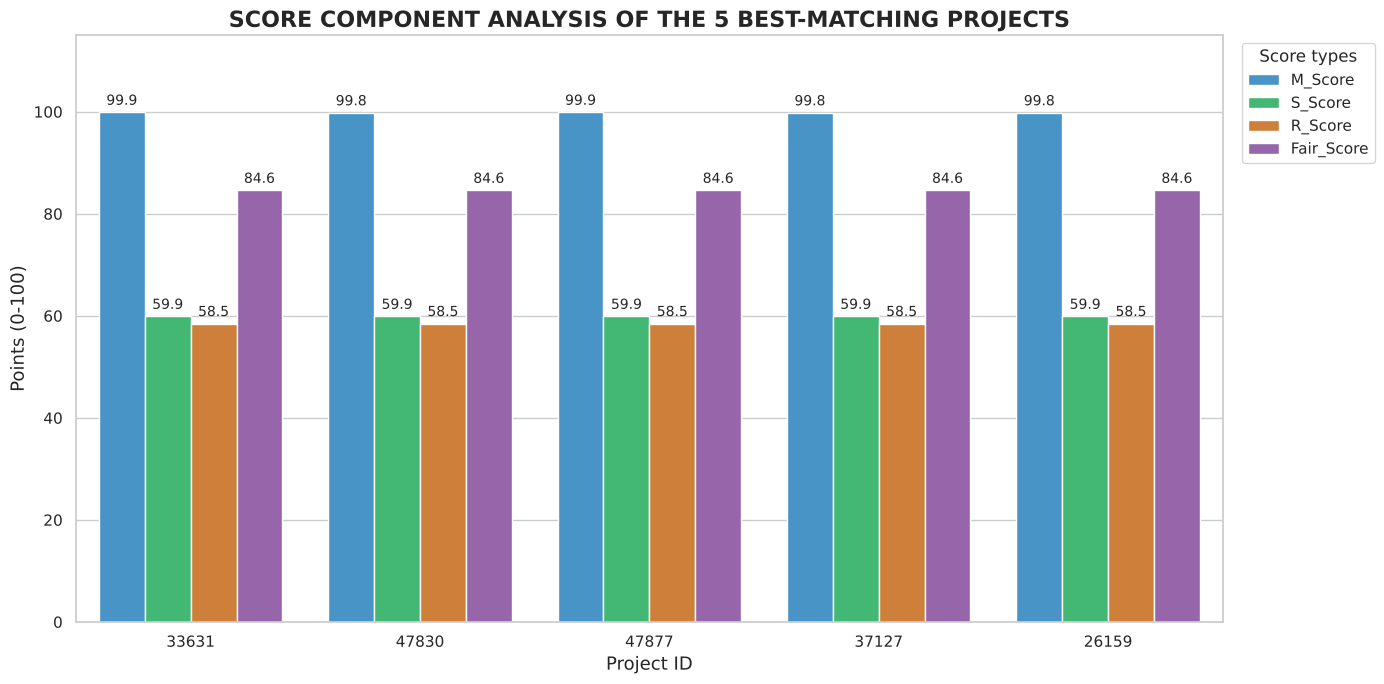


✅ Success! Chart saved as 'IP6_results_chart.png'.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("IP 6 started: visualizing the results...")

# 1. Load the data
try:
    df = pd.read_csv("IP5_final_fair_ranking.csv")
    df_top5 = df.head(5).copy()
    
    # --- FIX: add the R_Score column ---
    # We enter the value from IP 4 here as a constant (your score was 58.49)
    df_top5['R_Score'] = 58.49
    
    # Shorten the names (take the ID from the link)
    df_top5['Short_Name'] = df_top5['link'].apply(lambda x: x.split('/')[-1].replace('_en', '').upper())
    
except FileNotFoundError:
    print("ERROR: CSV file not found.")
    raise

# 2. Chart settings
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# Melt the columns - R_Score now exists
df_melted = df_top5.melt(id_vars=['Short_Name'], 
                         value_vars=['M_Score', 'S_Score', 'R_Score', 'Fair_Score'],
                         var_name='Score_Type', 
                         value_name='Points')

# 3. Bar chart
palette = {"M_Score": "#3498db", "S_Score": "#2ecc71", "R_Score": "#e67e22", "Fair_Score": "#9b59b6"}
ax = sns.barplot(x='Short_Name', y='Points', hue='Score_Type', data=df_melted, palette=palette)

# 4. Decorations
plt.title('SCORE COMPONENT ANALYSIS OF THE 5 BEST-MATCHING PROJECTS', fontsize=16, fontweight='bold')
plt.ylabel('Points (0-100)', fontsize=13)
plt.xlabel('Project ID', fontsize=13)
plt.ylim(0, 115)
plt.legend(title='Score types', bbox_to_anchor=(1.01, 1), loc='upper left')

# Print the values
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=10)

plt.tight_layout()
plt.savefig("IP6_results_chart.png", dpi=300)
plt.show()

print("\n✅ Success! Chart saved as 'IP6_results_chart.png'.")

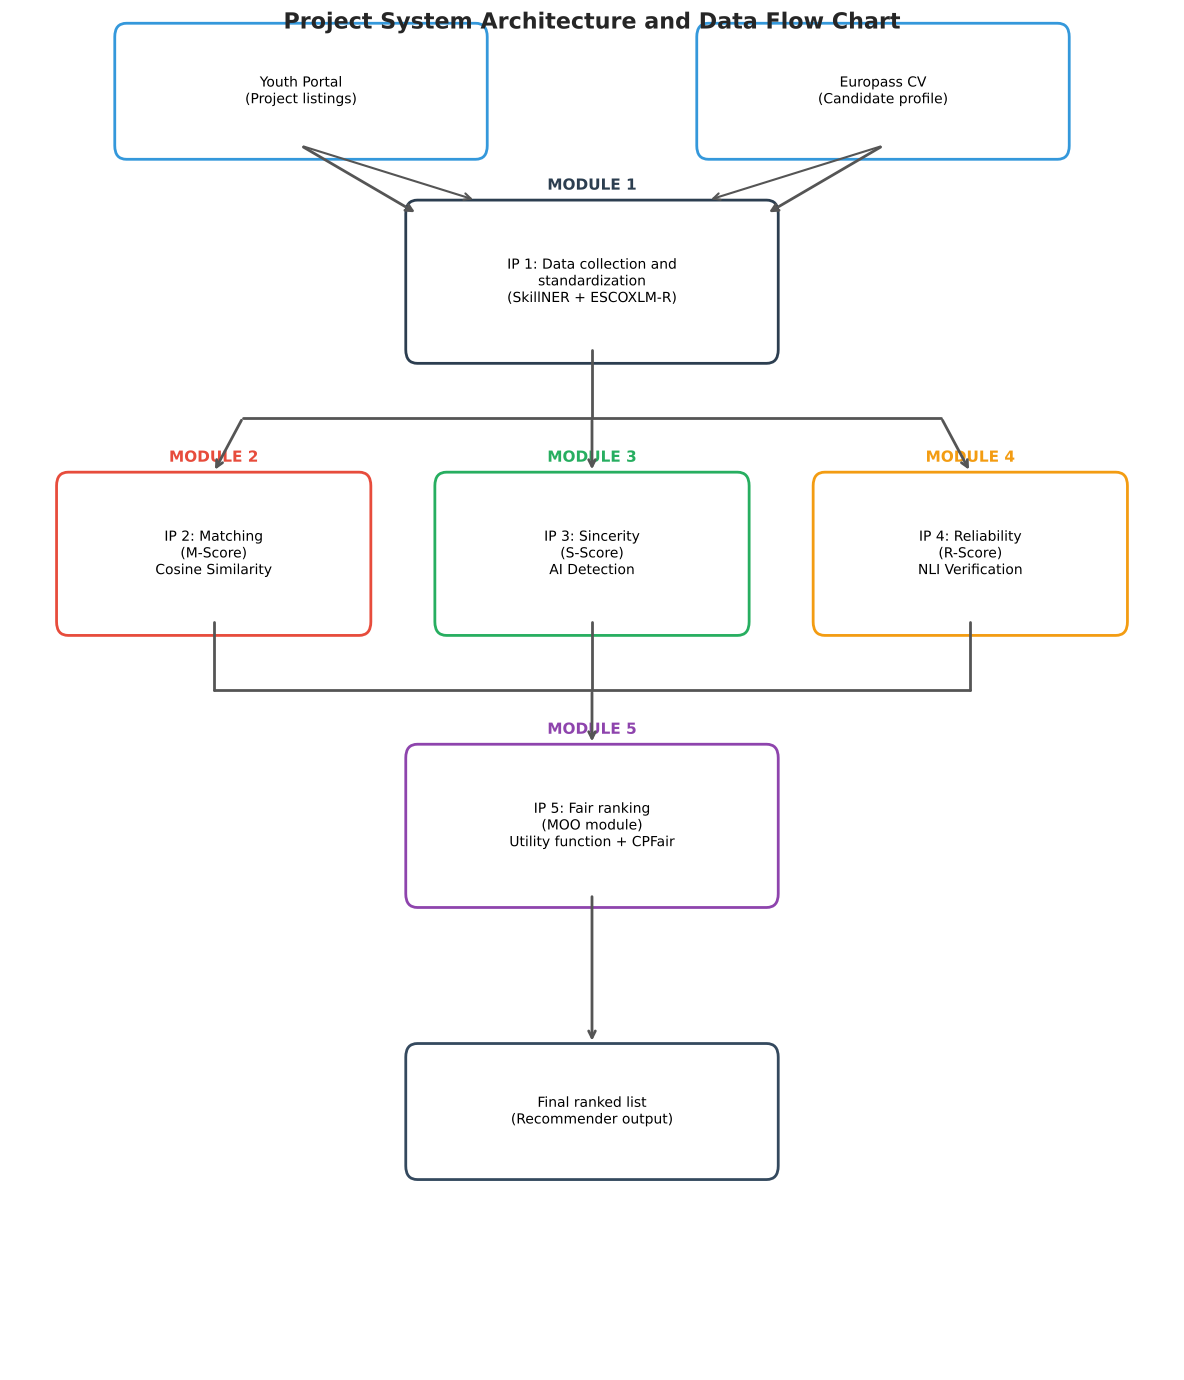


✅ Flow chart saved as 'system_flow_chart.png'.


In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_flowchart():
    fig, ax = plt.subplots(figsize=(12, 14))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off') # Hide the axes

    # --- BOX DRAWING FUNCTION ---
    def create_box(x, y, width, height, text, color, title=None):
        # Box
        rect = patches.FancyBboxPatch((x, y), width, height, 
                                      boxstyle="round,pad=0.1", 
                                      linewidth=2, edgecolor=color, facecolor='white')
        ax.add_patch(rect)
        # Inner text
        ax.text(x + width/2, y + height/2, text, 
                ha='center', va='center', fontsize=10, color='black')
        # Title (above the box, if given)
        if title:
            ax.text(x + width/2, y + height + 0.15, title, 
                    ha='center', va='bottom', fontsize=11, fontweight='bold', color=color)
        return (x + width/2, y) # Bottom center point (for arrows)

    # --- ARROW DRAWING FUNCTION ---
    def draw_arrow(start_coords, end_coords):
        ax.annotate("", xy=end_coords, xytext=start_coords,
                    arrowprops=dict(arrowstyle="->", lw=2, color="#555555"))

    # --- LAYER 1: DATA SOURCES (INPUTS) ---
    create_box(1, 9, 3, 0.8, "Youth Portal\n(Project listings)", "#3498db")
    create_box(6, 9, 3, 0.8, "Europass CV\n(Candidate profile)", "#3498db")

    # --- LAYER 2: IP 1 (DATA PROCESSING) ---
    ip1_pos = create_box(3.5, 7.5, 3, 1, "IP 1: Data collection and\nstandardization\n(SkillNER + ESCOXLM-R)", "#2c3e50", "MODULE 1")
    
    # Arrows (from the inputs to IP 1)
    draw_arrow((2.5, 9), (3.5, 8.5)) # Youth Portal -> close to the center, not the top-left corner
    draw_arrow((7.5, 9), (6.5, 8.5)) # CV -> close to the center, not the top-right corner
    ax.plot([2.5, 2.5, 3.5], [9, 8.5, 8.5], color="#555", lw=0) # Reference only
    
    # Manual arrow correction
    ax.annotate("", xy=(4, 8.6), xytext=(2.5, 9), arrowprops=dict(arrowstyle="->", lw=1.5, color="#555"))
    ax.annotate("", xy=(6, 8.6), xytext=(7.5, 9), arrowprops=dict(arrowstyle="->", lw=1.5, color="#555"))

    # --- LAYER 3: SCORING MODULES (PARALLEL PROCESSING) ---
    # Common distribution point
    ax.plot([5, 5], [7.5, 7], color="#555", lw=2) # Line going down from IP 1
    ax.plot([2, 8], [7, 7], color="#555", lw=2)   # Horizontal distribution line

    # Modules
    create_box(0.5, 5.5, 2.5, 1, "IP 2: Matching\n(M-Score)\nCosine Similarity", "#e74c3c", "MODULE 2")
    create_box(3.75, 5.5, 2.5, 1, "IP 3: Sincerity\n(S-Score)\nAI Detection", "#27ae60", "MODULE 3")
    create_box(7, 5.5, 2.5, 1, "IP 4: Reliability\n(R-Score)\nNLI Verification", "#f39c12", "MODULE 4")

    # Arrows from the distribution point to the modules
    draw_arrow((2, 7), (1.75, 6.6))
    draw_arrow((5, 7), (5, 6.6))
    draw_arrow((8, 7), (8.25, 6.6))

    # --- LAYER 4: IP 5 (MERGING) ---
    # Collection point
    ax.plot([1.75, 1.75], [5.5, 5], color="#555", lw=2) # IP 2 output
    ax.plot([5, 5], [5.5, 5], color="#555", lw=2)       # IP 3 output
    ax.plot([8.25, 8.25], [5.5, 5], color="#555", lw=2) # IP 4 output
    ax.plot([1.75, 8.25], [5, 5], color="#555", lw=2)   # Horizontal collector

    create_box(3.5, 3.5, 3, 1, "IP 5: Fair ranking\n(MOO module)\nUtility function + CPFair", "#8e44ad", "MODULE 5")
    draw_arrow((5, 5), (5, 4.6))

    # --- LAYER 5: OUTPUT ---
    create_box(3.5, 1.5, 3, 0.8, "Final ranked list\n(Recommender output)", "#34495e")
    draw_arrow((5, 3.5), (5, 2.4))

    # Title
    plt.title("Project System Architecture and Data Flow Chart", fontsize=16, fontweight='bold', y=0.98)
    
    # Save
    plt.tight_layout()
    plt.savefig("system_flow_chart.png", dpi=300)
    plt.show()

draw_flowchart()
print("\n✅ Flow chart saved as 'system_flow_chart.png'.")